# Hotel Booking Cancellation Prediction: End-to-End Project

**Goal:** predict, at the moment a booking is made, how likely it is to be cancelled, so the hotel can ask high-risk guests for a deposit and plan overbooking safely.

**Data:** 119,390 real bookings from a city hotel and a resort hotel in Portugal, arrivals from July 2015 to August 2017 ([source](https://github.com/rfordatascience/tidytuesday/tree/master/data/2020/2020-02-11); Antonio, Almeida & Nunes, 2019, *Data in Brief*).

**Workflow** (CRISP-DM): business understanding → data understanding → data preparation → modelling → evaluation → deployment & monitoring.

| # | Step | # | Step |
|---|---|---|---|
| 1 | Business understanding | 10 | Preprocessing pipeline |
| 2 | Load data | 11 | Model comparison |
| 3 | First look | 12 | Decision threshold |
| 4 | Data quality checks | 13 | Final test (once) |
| 5 | Leakage check | 14 | Model explanation |
| 6 | Cleaning | 15 | Save model + live scoring |
| 7 | Feature engineering | 16 | Monitoring (drift) |
| 8 | Time-based split | 17 | Business summary |
| 9 | Exploratory analysis | | |

## 1. Business understanding

- **Problem:** about 37% of bookings are cancelled, leaving rooms empty and losing revenue.
- **Use of the model:** (1) high-risk bookings get a deposit request or reminder; (2) the sum of probabilities gives expected cancellations for overbooking decisions.
- **Success criteria:** good ranking (ROC-AUC), and **at least 80% precision** on flagged bookings, so genuine guests aren't bothered unnecessarily.
- **Prediction time = booking time.** Only information known when the booking is made may be used. This rule decides which columns are allowed.

## 2. Load data

In [ ]:
from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

DATA = Path("data/hotel_bookings.csv")
URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"
if not DATA.exists():                      # download once if the file isn't there
    DATA.parent.mkdir(exist_ok=True)
    pd.read_csv(URL).to_csv(DATA, index=False)

# say exactly which values mean "missing"; load ID columns as text
df_raw = pd.read_csv(DATA, keep_default_na=False, na_values=["NULL", "NA", ""],
                     dtype={"agent": str, "company": str})
print(df_raw.shape)
df_raw.head()

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 3. First look

In [ ]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [ ]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


## 4. Data quality checks

An automated red-flag scan runs first on every new dataset. A flag means **investigate or ask**, not delete.

In [ ]:
def red_flags(df, target):
    flags = []
    n = len(df)
    if df.duplicated().sum():
        flags.append(("ALL ROWS", "duplicates", f"{df.duplicated().sum()} identical rows: is there a unique ID?"))
    for col in df.columns.drop(target):
        s = df[col]
        miss = s.isna().mean()
        if miss > 0.3:
            flags.append((col, "missing", f"{miss:.0%} missing"))
        if s.nunique() <= 1:
            flags.append((col, "constant", "only one value"))
        if pd.api.types.is_numeric_dtype(s):
            if (s < 0).any():
                flags.append((col, "negative", f"{(s < 0).sum()} negative values"))
            q99 = s.quantile(0.99)
            if s.max() > 10 * max(q99, 1):
                flags.append((col, "outlier", f"max {s.max():g} vs 99th percentile {q99:g}"))
        else:
            odd = s.astype(str).str.strip().str.lower().isin(
                ["undefined", "unknown", "null", "na", "n/a", "none", "-", "?", ""]).sum()
            if odd:
                flags.append((col, "hidden missing", f"{odd} values like 'Undefined'"))
            if s.nunique() > 50:
                flags.append((col, "high cardinality", f"{s.nunique()} categories"))
        if s.nunique() <= 30:      # leakage scan: does a common value give an (almost) perfect answer?
            g = df.groupby(s.astype(str))[target].agg(["mean", "size"])
            g = g[g["size"] >= 0.01 * n]
            extreme = g[(g["mean"] <= 0.01) | (g["mean"] >= 0.99)]
            if len(extreme):
                detail = ", ".join(f"{i}: {m:.0%} ({int(c)} rows)" for i, (m, c) in extreme.iterrows())
                flags.append((col, "POSSIBLE LEAKAGE", f"target rate {detail}"))
        if any(w in col.lower() for w in ["status", "result", "outcome", "final", "assigned", "closed", "approved"]):
            flags.append((col, "check timing", "name suggests it's filled AFTER the outcome"))
    return pd.DataFrame(flags, columns=["column", "flag", "detail"])

pd.set_option("display.max_colwidth", 100)
red_flags(df_raw, "is_canceled")

,column,flag,detail
0,ALL ROWS,duplicates,31994 identical rows: is there a unique ID?
1,adults,outlier,max 55 vs 99th percentile 3
2,meal,hidden missing,1169 values like 'Undefined'
3,country,high cardinality,177 categories
4,market_segment,hidden missing,2 values like 'Undefined'
5,distribution_channel,hidden missing,5 values like 'Undefined'
6,previous_cancellations,outlier,max 26 vs 99th percentile 1
7,previous_bookings_not_canceled,outlier,max 72 vs 99th percentile 3
8,assigned_room_type,check timing,name suggests it's filled AFTER the outcome
9,deposit_type,POSSIBLE LEAKAGE,target rate Non Refund: 99% (14587 rows)


In [ ]:
print("missing %:\n", (df_raw.isna().mean() * 100).round(1).sort_values(ascending=False).head(4))
guests = df_raw["adults"] + df_raw["children"].fillna(0) + df_raw["babies"]
print("\nzero-guest bookings:", (guests == 0).sum())
print("overall cancel rate:", round(df_raw["is_canceled"].mean(), 3))

missing %:
 company    94.3
agent      13.7
country     0.4
hotel       0.0
dtype: float64

zero-guest bookings: 180
overall cancel rate: 0.37


## 5. Leakage check: is each column known at booking time?

In [ ]:
y = df_raw["is_canceled"]
print(pd.crosstab(df_raw["reservation_status"], y), "\n")
print("cancel rate when parking > 0     :", round(y[df_raw["required_car_parking_spaces"] > 0].mean(), 3))
print("cancel rate when room was changed:", round(y[df_raw["reserved_room_type"] != df_raw["assigned_room_type"]].mean(), 3))
print("cancel rate when booking changed :", round(y[df_raw["booking_changes"] > 0].mean(), 3))

is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207 

cancel rate when parking > 0     : 0.0
cancel rate when room was changed: 0.054
cancel rate when booking changed : 0.157


| Column | Why it leaks | Decision |
|---|---|---|
| `reservation_status`, `reservation_status_date` | They *are* the outcome | Drop |
| `required_car_parking_spaces` | 0% cancellations when > 0: recorded on arrival | Drop |
| `assigned_room_type` | Assigned at check-in; changed rooms cancel only 5% | Drop |
| `booking_changes` | Accumulates until arrival or cancellation | Drop |
| `deposit_type` | Flagged (Non Refund 99% cancelled) but **known at booking** | Keep; ask the business |

## 6. Cleaning

Written as functions, so the **same code** cleans the training data and every live booking.

In [ ]:
MONTHS = {m: i for i, m in enumerate(
    ["January", "February", "March", "April", "May", "June", "July",
     "August", "September", "October", "November", "December"], start=1)}

# Columns filled in AFTER the outcome (at check-in or cancellation): never used as inputs
LEAKAGE = ["reservation_status", "reservation_status_date", "assigned_room_type",
           "booking_changes", "required_car_parking_spaces"]


def clean_bookings(df):
    """Rule-based cleaning. Learns nothing from the data, so it is safe for training AND live bookings."""
    df = df.copy()
    df["meal"] = df["meal"].replace({"Undefined": "SC"})            # data dictionary: Undefined = SC (no meal)
    for col in ["market_segment", "distribution_channel"]:
        df[col] = df[col].replace({"Undefined": np.nan})
    df["children"] = pd.to_numeric(df["children"], errors="coerce").fillna(0)
    df["agent"] = df["agent"].fillna("none")                        # no agent = booked directly
    df["has_company"] = df["company"].notna().astype(int)           # 94% missing -> keep only a flag
    df.loc[(df["adr"] < 0) | (df["adr"] > 1000), "adr"] = np.nan    # impossible prices
    df["arrival_date"] = pd.to_datetime(pd.DataFrame({
        "year": df["arrival_date_year"],
        "month": df["arrival_date_month"].map(MONTHS),
        "day": df["arrival_date_day_of_month"]}))
    return df.drop(columns=LEAKAGE + ["company"], errors="ignore")


def add_features(df):
    """Business features that are known at booking time."""
    df = df.copy()
    df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
    df["total_guests"] = df["adults"] + df["children"] + df["babies"]
    df["has_kids"] = ((df["children"] + df["babies"]) > 0).astype(int)
    df["has_agent"] = (df["agent"] != "none").astype(int)
    df["arrival_month"] = df["arrival_date"].dt.month
    df["arrival_weekday"] = df["arrival_date"].dt.day_name()
    return df

In [ ]:
df = clean_bookings(df_raw)
guests = df["adults"] + df["children"] + df["babies"]
quarantine = df[guests == 0]                     # invalid rows: set aside, not silently deleted
df = df[guests > 0].reset_index(drop=True)
print(df.shape, "| quarantined:", len(quarantine))

(119210, 28) | quarantined: 180


**Decisions log**

| Issue | Decision | Reason |
|---|---|---|
| `meal = "Undefined"` (1,169) | → `SC` | Data dictionary: Undefined and SC both mean no meal package |
| `Undefined` segment or channel (7) | → missing | Imputed later |
| `agent` missing | → `"none"` | No agent means a direct booking |
| `company` 94% missing | Keep only a `has_company` flag | Too sparse to use directly |
| Price < 0 or > 1,000 (2 rows) | → missing | Impossible values |
| Zero guests (180) | Quarantined | Not a real stay |
| 31,994 identical rows | Kept | No booking ID, so they may be group bookings; identical rows share an arrival date, so the time split keeps each set together |

## 7. Feature engineering

In [ ]:
df = add_features(df)
df[["total_nights", "total_guests", "has_kids", "has_agent", "arrival_month", "arrival_weekday"]].head()

,total_nights,total_guests,has_kids,has_agent,arrival_month,arrival_weekday
0,0,2.0,0,0,7,Wednesday
1,0,2.0,0,0,7,Wednesday
2,1,1.0,0,0,7,Wednesday
3,1,1.0,0,1,7,Wednesday
4,2,2.0,0,1,7,Wednesday


## 8. Time-based split

The model will score **future** bookings, so: train on the oldest arrivals, validate on the next months (to choose the model and threshold), and test on the newest months, **used once**.

In [ ]:
train = df[df["arrival_date"] < "2017-01-01"]
valid = df[(df["arrival_date"] >= "2017-01-01") & (df["arrival_date"] < "2017-05-01")]
test = df[df["arrival_date"] >= "2017-05-01"]
for name, part in [("train", train), ("valid", valid), ("test ", test)]:
    print(f"{name}: {len(part):6,} rows | {part['arrival_date'].min().date()} to "
          f"{part['arrival_date'].max().date()} | cancel rate {part['is_canceled'].mean():.3f}")

train: 78,590 rows | 2015-07-01 to 2016-12-31 | cancel rate 0.362


valid: 18,443 rows | 2017-01-01 to 2017-04-30 | cancel rate 0.365
test : 22,177 rows | 2017-05-01 to 2017-08-31 | cancel rate 0.406


## 9. Exploratory analysis (training data only)

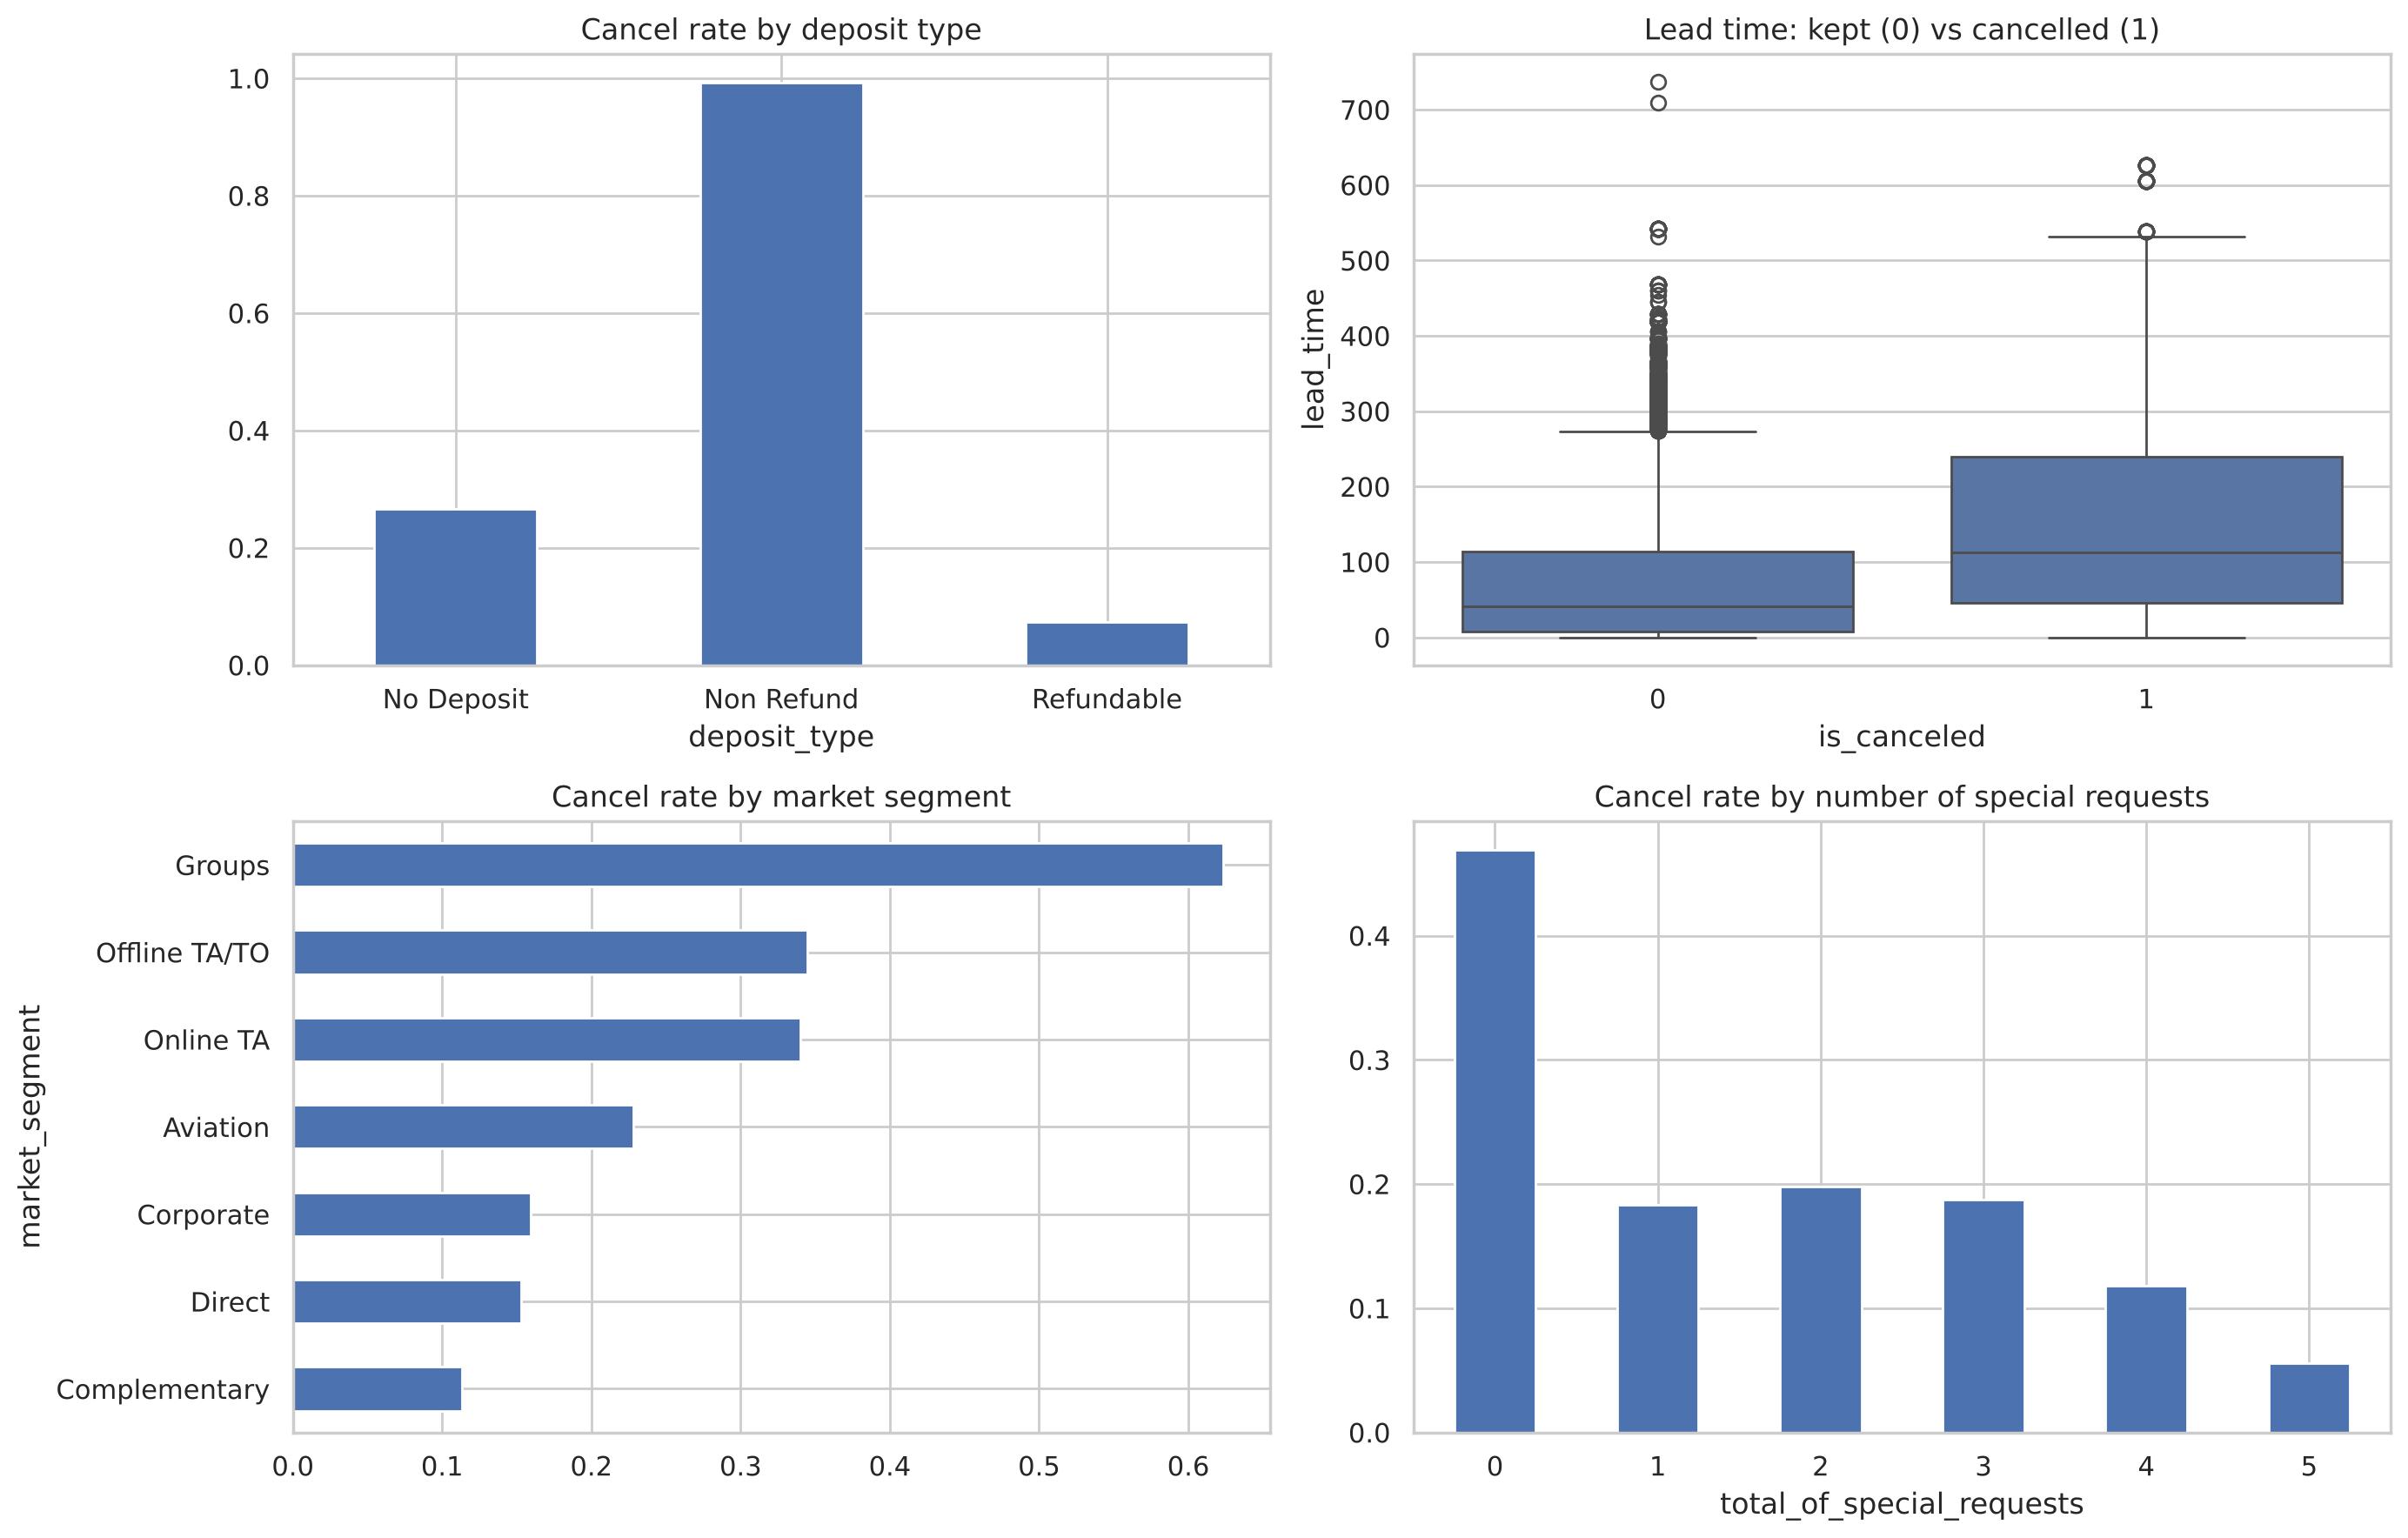

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
train.groupby("deposit_type")["is_canceled"].mean().plot(kind="bar", ax=axes[0, 0], rot=0, title="Cancel rate by deposit type")
sns.boxplot(data=train, x="is_canceled", y="lead_time", ax=axes[0, 1]).set_title("Lead time: kept (0) vs cancelled (1)")
train.groupby("market_segment")["is_canceled"].mean().sort_values().plot(kind="barh", ax=axes[1, 0], title="Cancel rate by market segment")
train.groupby("total_of_special_requests")["is_canceled"].mean().plot(kind="bar", ax=axes[1, 1], rot=0, title="Cancel rate by number of special requests")
plt.tight_layout(); plt.show()

**Findings:**
- Non Refund deposits cancel **99%** of the time. This is counter-intuitive, so it's a question for the business.
- The Groups segment cancels **62%** of the time.
- Cancelled bookings were made a median of **113 days** ahead, against **41 days** for kept bookings.
- **No special requests** means 47% cancellations, against about 19% with any request.

## 10. Preprocessing pipeline

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

LOG_NUM = ["lead_time", "days_in_waiting_list", "previous_cancellations", "previous_bookings_not_canceled"]
NUM = ["adr", "total_nights", "total_guests", "total_of_special_requests", "arrival_month"]
FLAGS = ["is_repeated_guest", "has_kids", "has_agent", "has_company"]
CAT = ["hotel", "meal", "market_segment", "distribution_channel", "reserved_room_type",
       "deposit_type", "customer_type", "arrival_weekday"]
HIGH_CAT = ["country", "agent"]            # 177 countries, 333 agents -> rare ones grouped
FEATURES = LOG_NUM + NUM + FLAGS + CAT + HIGH_CAT
TARGET = "is_canceled"

preprocess = ColumnTransformer([
    ("log_num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("log", FunctionTransformer(np.log1p)),
                          ("scale", StandardScaler())]), LOG_NUM),
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUM),
    ("flags", "passthrough", FLAGS),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT),
    ("high_cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="unknown")),
                           ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                    min_frequency=200, sparse_output=False))]), HIGH_CAT),
])

X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

## 11. Model comparison (on validation)

In [ ]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

models = {
    "Baseline (always 'not cancelled')": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=300, random_state=42),
}
results, fitted = [], {}
for name, clf in models.items():
    pipe = Pipeline([("preprocess", clone(preprocess)), ("model", clf)])
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_valid)[:, 1]
    results.append({"model": name, "ROC-AUC": roc_auc_score(y_valid, p),
                    "PR-AUC": average_precision_score(y_valid, p)})
    fitted[name] = pipe
pd.DataFrame(results).round(3)

,model,ROC-AUC,PR-AUC
0,Baseline (always 'not cancelled'),0.500,0.365
1,Logistic Regression,0.888,0.842
2,Gradient Boosting,0.891,0.848


## 12. Decision threshold (chosen on validation)

threshold 0.3: precision 0.75, recall 0.73
threshold 0.4: precision 0.80, recall 0.68
threshold 0.5: precision 0.81, recall 0.63
threshold 0.6: precision 0.84, recall 0.57
threshold 0.7: precision 0.89, recall 0.50

Chosen threshold 0.41 -> precision 0.80, recall 0.67


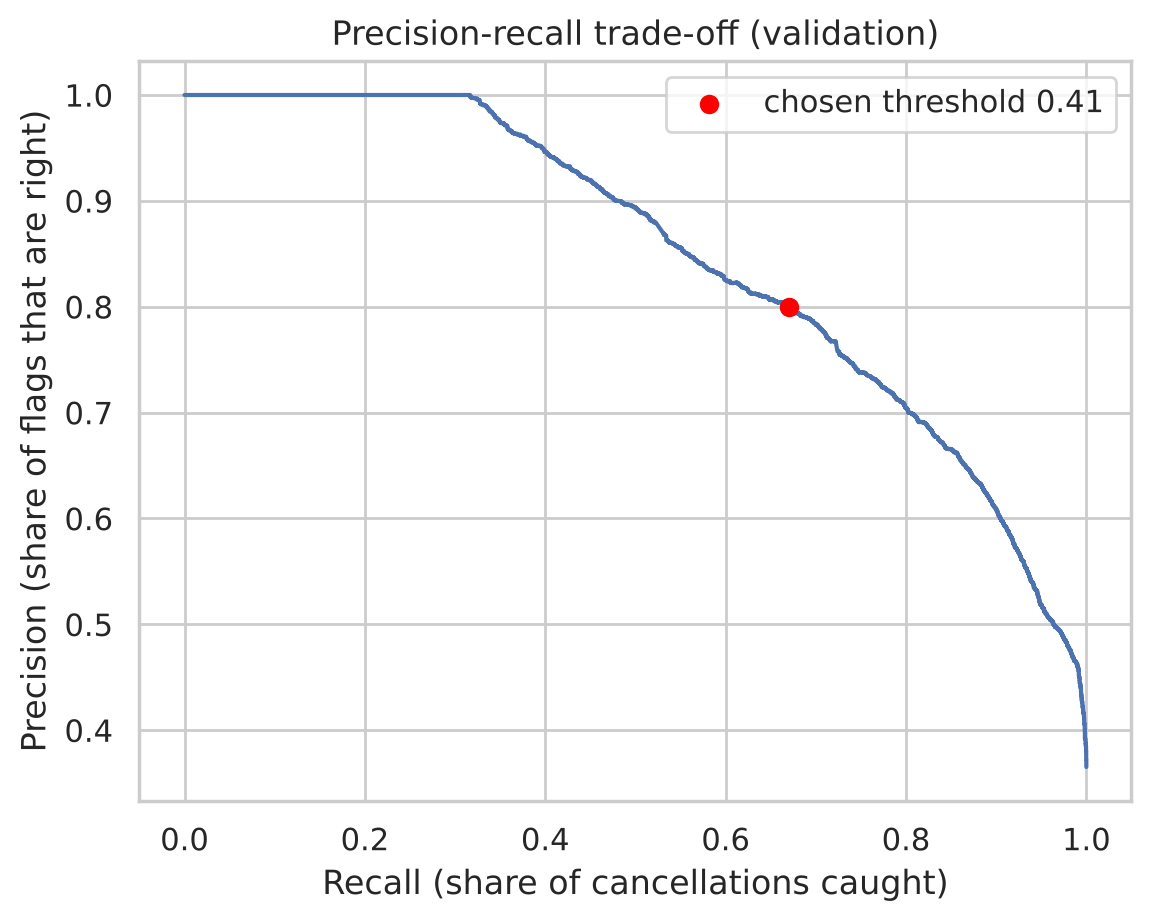

In [ ]:
from sklearn.metrics import precision_recall_curve, precision_score, recall_score

best = fitted["Gradient Boosting"]
p_valid = best.predict_proba(X_valid)[:, 1]
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (p_valid >= t).astype(int)
    print(f"threshold {t}: precision {precision_score(y_valid, pred):.2f}, recall {recall_score(y_valid, pred):.2f}")

precision, recall, thresholds = precision_recall_curve(y_valid, p_valid)
i = np.where(precision[:-1] >= 0.80)[0][0]          # lowest threshold with >= 80% precision
THRESHOLD = thresholds[i]
print(f"\nChosen threshold {THRESHOLD:.2f} -> precision {precision[i]:.2f}, recall {recall[i]:.2f}")

plt.plot(recall, precision)
plt.scatter(recall[i], precision[i], color="red", zorder=3, label=f"chosen threshold {THRESHOLD:.2f}")
plt.xlabel("Recall (share of cancellations caught)"); plt.ylabel("Precision (share of flags that are right)")
plt.title("Precision-recall trade-off (validation)"); plt.legend(); plt.show()

## 13. Final test (run once)

Validation ROC-AUC: 0.891
Test ROC-AUC      : 0.855
              precision    recall  f1-score   support

        kept      0.764     0.890     0.822     13179
   cancelled      0.788     0.598     0.680      8998

    accuracy                          0.771     22177
   macro avg      0.776     0.744     0.751     22177
weighted avg      0.774     0.771     0.765     22177

Cancellations: 8,998 | caught in advance: 5,382 | missed: 3,616 | false alarms: 1,452


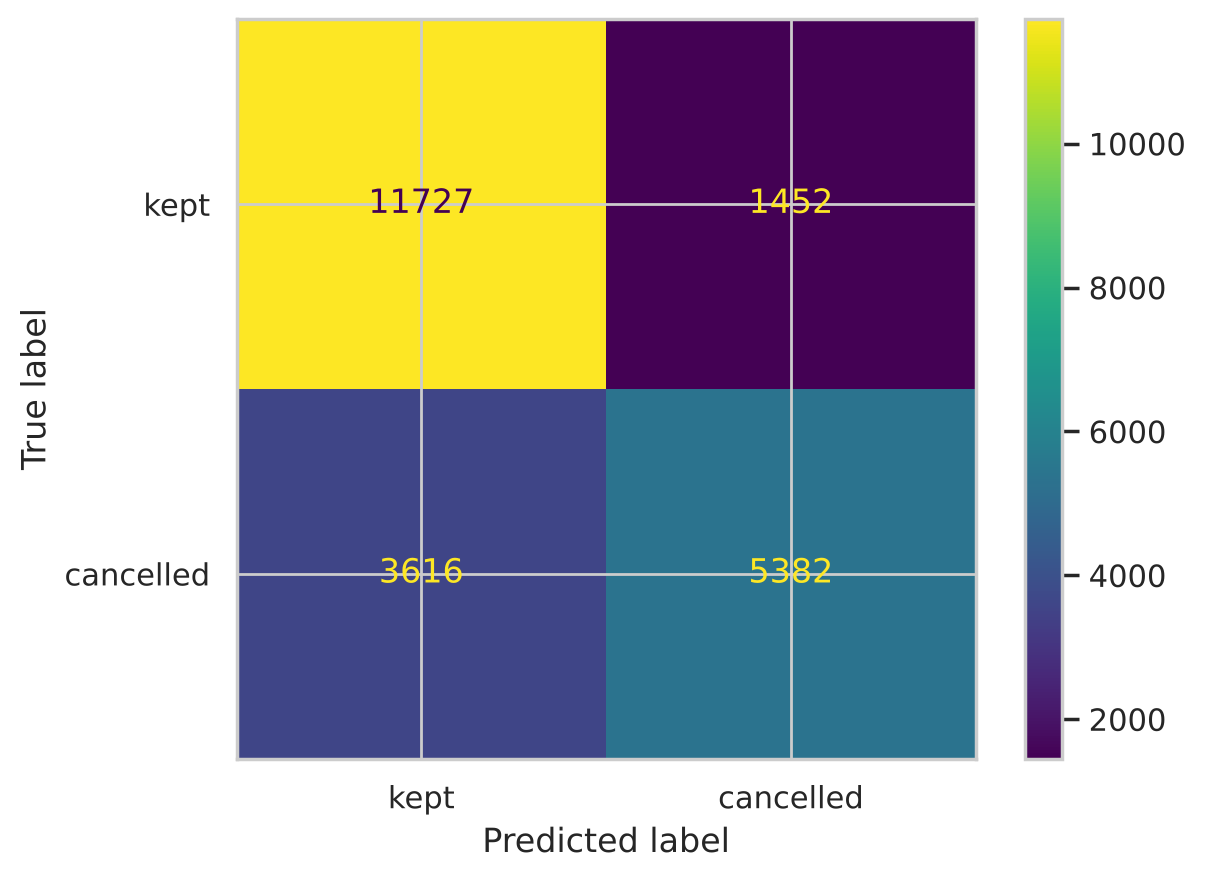

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

p_test = best.predict_proba(X_test)[:, 1]
pred_test = (p_test >= THRESHOLD).astype(int)
print("Validation ROC-AUC:", round(roc_auc_score(y_valid, p_valid), 3))
print("Test ROC-AUC      :", round(roc_auc_score(y_test, p_test), 3))
print(classification_report(y_test, pred_test, target_names=["kept", "cancelled"], digits=3))
caught = int(((pred_test == 1) & (y_test == 1)).sum())
missed = int(((pred_test == 0) & (y_test == 1)).sum())
false_alarms = int(((pred_test == 1) & (y_test == 0)).sum())
print(f"Cancellations: {int(y_test.sum()):,} | caught in advance: {caught:,} | missed: {missed:,} | false alarms: {false_alarms:,}")
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["kept", "cancelled"]); plt.show()

In [ ]:
monthly = (test.assign(predicted=p_test)
               .groupby(test["arrival_date"].dt.month_name(), sort=False)
               .agg(actual_cancellations=("is_canceled", "sum"),
                    predicted_cancellations=("predicted", "sum"))
               .round(0))
monthly

,actual_cancellations,predicted_cancellations
arrival_date,,
May,2762,2233.0
June,2438,2055.0
July,1984,1508.0
August,1814,1382.0


## 14. Model explanation

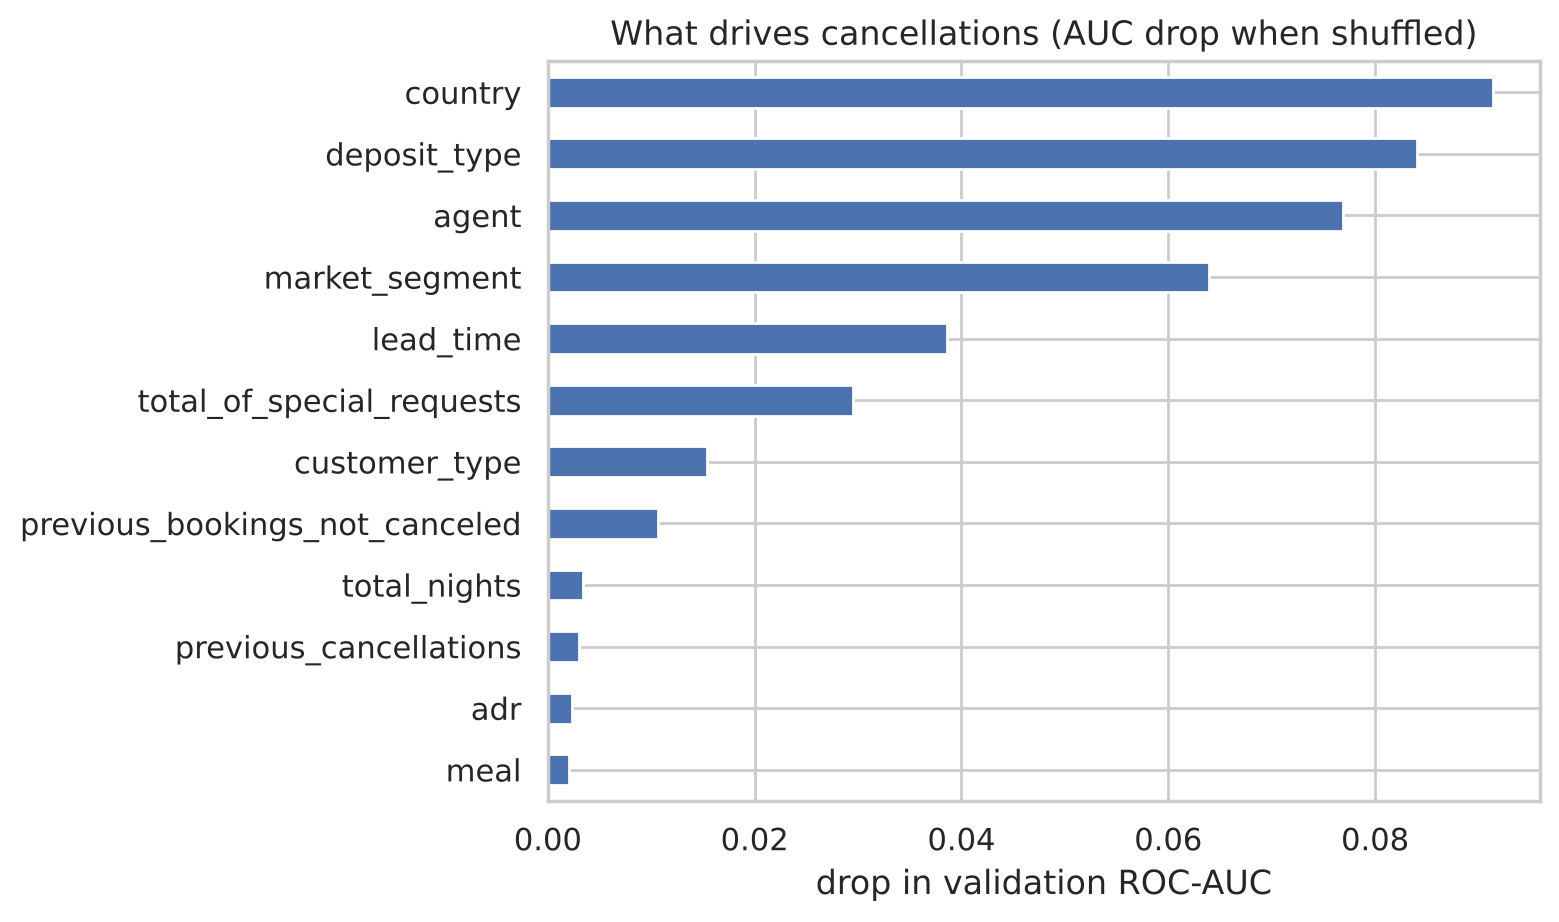

In [ ]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(best, X_valid, y_valid, scoring="roc_auc", n_repeats=3, random_state=42, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
importance.tail(12).plot(kind="barh", title="What drives cancellations (AUC drop when shuffled)")
plt.xlabel("drop in validation ROC-AUC"); plt.show()

**Sensitivity check:** `country` is the top feature, but it's unclear whether it's recorded at booking or at check-in. How much does the model depend on it?

In [ ]:
pipe_nc = Pipeline([("preprocess", clone(preprocess)),
                    ("model", HistGradientBoostingClassifier(max_iter=300, random_state=42))])
pipe_nc.fit(X_train.assign(country="unknown"), y_train)
auc_nc = roc_auc_score(y_valid, pipe_nc.predict_proba(X_valid.assign(country="unknown"))[:, 1])
print("validation AUC with country   :", round(roc_auc_score(y_valid, p_valid), 3))
print("validation AUC without country:", round(auc_nc, 3))
train.groupby("country")["is_canceled"].agg(["mean", "size"]).sort_values("size", ascending=False).head(6).round(2)

validation AUC with country   : 0.891
validation AUC without country: 0.861


,mean,size
country,,
PRT,0.56,35565
GBR,0.16,6937
FRA,0.15,6502
ESP,0.22,5950
DEU,0.13,4387
ITA,0.32,2449


## 15. Save the model and score a live booking

In [ ]:
Path("models").mkdir(exist_ok=True)
joblib.dump(best, "models/hotel_cancel_model.joblib")
model_card = {
    "model": "HistGradientBoostingClassifier in a scikit-learn Pipeline",
    "trained_on": "arrivals Jul-2015 to Dec-2016",
    "features": FEATURES,
    "threshold": round(float(THRESHOLD), 3),
    "validation_roc_auc": round(roc_auc_score(y_valid, p_valid), 3),
    "test_roc_auc": round(roc_auc_score(y_test, p_test), 3),
    "open_questions": ["Is country recorded at booking or at check-in?",
                       "Why do Non Refund deposits cancel 99% of the time?"],
}
Path("models/model_card.json").write_text(json.dumps(model_card, indent=2))

model = joblib.load("models/hotel_cancel_model.joblib")    # what the booking system does at start-up

def score_booking(booking):
    row = add_features(clean_bookings(pd.DataFrame([booking])))   # SAME code as training
    prob = model.predict_proba(row[FEATURES])[0, 1]
    action = "HIGH RISK: ask for deposit / send reminder" if prob >= THRESHOLD else "normal"
    return round(float(prob), 3), action

new_booking = {
    "hotel": "City Hotel", "lead_time": 210, "arrival_date_year": 2017,
    "arrival_date_month": "October", "arrival_date_day_of_month": 14,
    "stays_in_weekend_nights": 1, "stays_in_week_nights": 2, "adults": 2,
    "children": None, "babies": 0, "meal": "BB", "country": "IND",
    "market_segment": "Online TA", "distribution_channel": "TA/TO",
    "is_repeated_guest": 0, "previous_cancellations": 0,
    "previous_bookings_not_canceled": 0, "reserved_room_type": "A",
    "deposit_type": "No Deposit", "agent": "9", "company": None,
    "days_in_waiting_list": 0, "customer_type": "Transient", "adr": 120.0,
    "total_of_special_requests": 0,
}
repeat_guest = {**new_booking, "lead_time": 10, "market_segment": "Direct", "distribution_channel": "Direct",
                "is_repeated_guest": 1, "previous_bookings_not_canceled": 3, "agent": None,
                "total_of_special_requests": 2, "country": "GBR"}
print("New booking  :", score_booking(new_booking))
print("Repeat guest :", score_booking(repeat_guest))

New booking  : (0.908, 'HIGH RISK: ask for deposit / send reminder')
Repeat guest : (0.014, 'normal')


The same logic is packaged in **`scoring.py`** (`CancellationScorer`), ready to be imported by a web service such as FastAPI.

## 16. Monitoring (drift)

PSI (Population Stability Index): below 0.1 is stable, 0.1–0.25 means watch, above 0.25 is an alert.

In [ ]:
def psi(expected, actual, bins=10):
    expected, actual = pd.Series(expected).dropna(), pd.Series(actual).dropna()
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.clip(np.histogram(expected, edges)[0] / len(expected), 1e-6, None)
    a = np.clip(np.histogram(actual, edges)[0] / len(actual), 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

p_train = best.predict_proba(X_train)[:, 1]
rows = [{"feature": c, "PSI": psi(train[c], test[c])}
        for c in ["lead_time", "adr", "total_nights", "total_of_special_requests"]]
rows.append({"feature": "model score", "PSI": psi(p_train, p_test)})
drift = pd.DataFrame(rows).round(3)
drift["status"] = pd.cut(drift["PSI"], [-np.inf, 0.1, 0.25, np.inf], labels=["stable", "watch", "ALERT"])
same_months_2016 = train[train["arrival_date"].dt.month.isin([5, 6, 7, 8])]
print("adr PSI vs the same months of 2016:", round(psi(same_months_2016["adr"], test["adr"]), 3))
drift

adr PSI vs the same months of 2016: 0.334


,feature,PSI,status
0,lead_time,0.196,watch
1,adr,0.932,ALERT
2,total_nights,0.049,stable
3,total_of_special_requests,0.080,stable
4,model score,0.127,watch


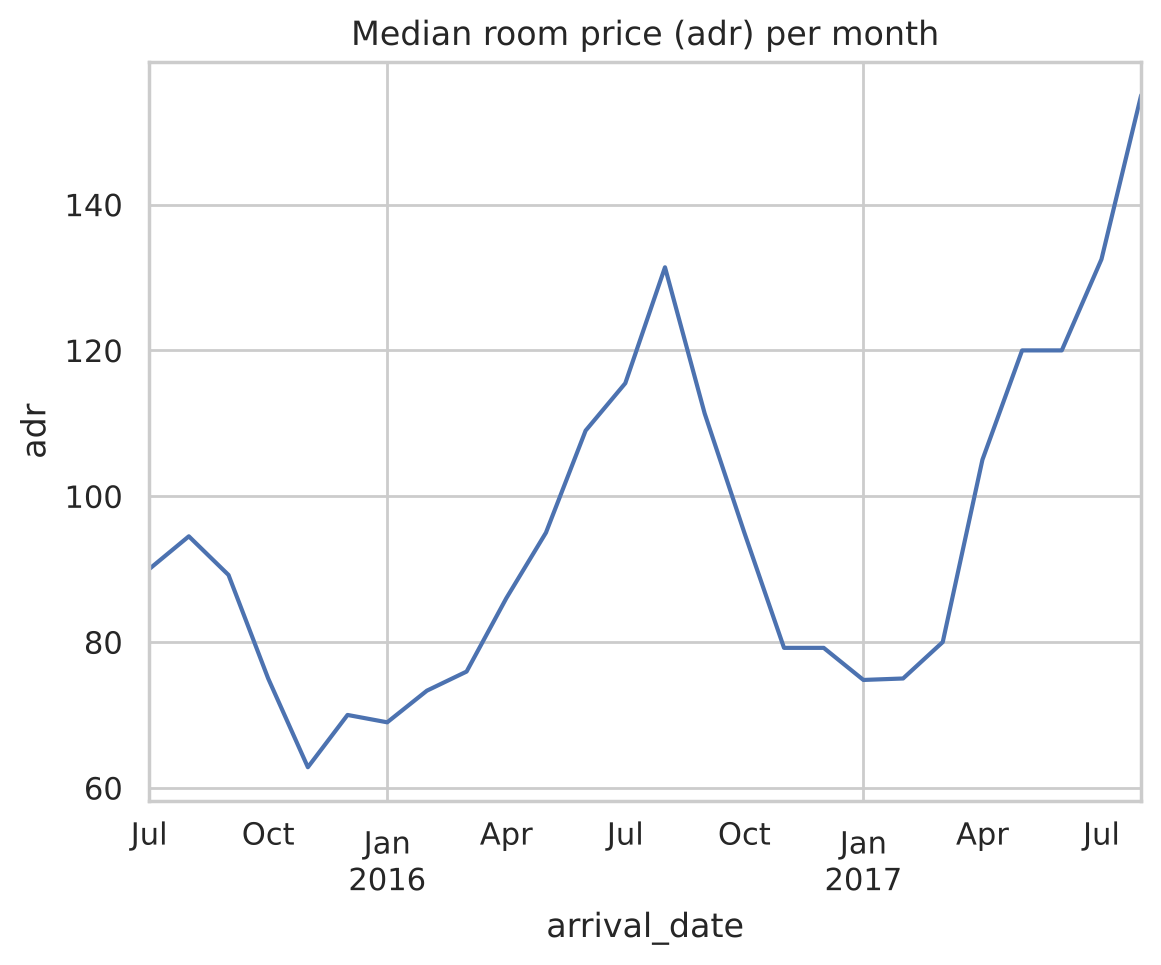

,bookings,actual_cancel_rate,avg_predicted,AUC
arrival_date,,,,
May,6305.0,0.438,0.354,0.892
June,5639.0,0.432,0.364,0.865
July,5310.0,0.374,0.284,0.823
August,4923.0,0.368,0.281,0.816


In [ ]:
df.groupby(df["arrival_date"].dt.to_period("M"))["adr"].median().plot(title="Median room price (adr) per month")
plt.ylabel("adr"); plt.show()

perf = (test.assign(score=p_test)
            .groupby(test["arrival_date"].dt.month_name(), sort=False)
            .apply(lambda g: pd.Series({"bookings": len(g),
                                        "actual_cancel_rate": g["is_canceled"].mean(),
                                        "avg_predicted": g["score"].mean(),
                                        "AUC": roc_auc_score(g["is_canceled"], g["score"])})))
perf.round(3)